# Level 2 – Task 1: Regression Analysis
**Dataset:** Boston Housing Dataset  
**Objective:** Predict house prices (MEDV) using Linear Regression  
**Tools:** Python, pandas, scikit-learn, matplotlib

## 1. Load the Dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import os

os.makedirs('plots', exist_ok=True)

columns = ['CRIM','ZN','INDUS','CHAS','NOX','RM','AGE','DIS','RAD','TAX','PTRATIO','B','LSTAT','MEDV']
df = pd.read_csv('../Data Set For Task/4) house Prediction Data Set.csv',
                 header=None, names=columns, sep='\s+')

print('Shape:', df.shape)
df.head()

<>:13: SyntaxWarning: invalid escape sequence '\s'
<>:13: SyntaxWarning: invalid escape sequence '\s'
C:\Users\YSS\AppData\Local\Temp\ipykernel_22424\2844284482.py:13: SyntaxWarning: invalid escape sequence '\s'
  header=None, names=columns, sep='\s+')


Shape: (506, 14)


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


## 2. Exploratory Check

In [2]:
print('Missing values:')
print(df.isnull().sum())
print('\nSummary statistics:')
df.describe()

Missing values:
CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64

Summary statistics:


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


## 3. Feature Selection
Use all features except the target (MEDV).

In [3]:
X = df.drop('MEDV', axis=1)
y = df['MEDV']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Train size:', X_train.shape[0], '| Test size:', X_test.shape[0])

Train size: 404 | Test size: 102


## 4. Train Linear Regression Model

In [4]:
model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print('Model trained successfully.')

Model trained successfully.


## 5. Evaluate the Model

In [5]:
r2  = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f'R-squared : {r2:.4f}')
print(f'MSE       : {mse:.4f}')
print(f'RMSE      : {rmse:.4f}')

R-squared : 0.6688
MSE       : 24.2911
RMSE      : 4.9286


## 6. Actual vs Predicted Plot

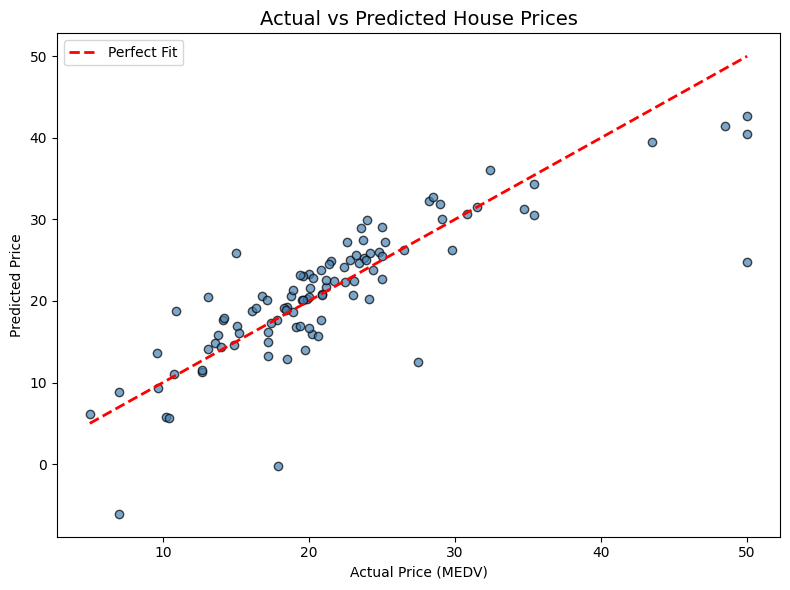

In [6]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.7, color='steelblue', edgecolors='black')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2, label='Perfect Fit')
plt.title('Actual vs Predicted House Prices', fontsize=14)
plt.xlabel('Actual Price (MEDV)')
plt.ylabel('Predicted Price')
plt.legend()
plt.tight_layout()
plt.savefig('plots/regression_actual_vs_predicted.png', dpi=150)
plt.show()

## 7. Feature Coefficients

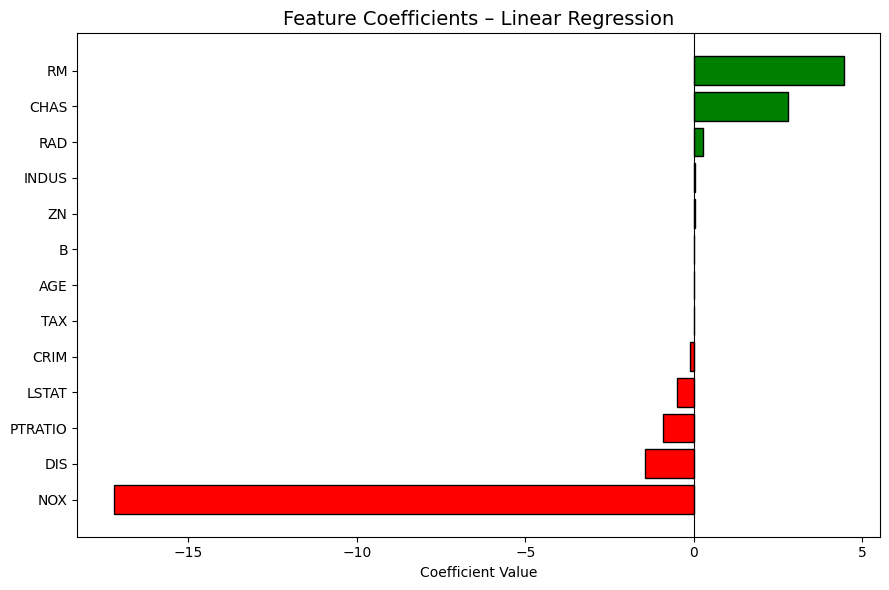

In [7]:
coef_df = pd.DataFrame({'Feature': X.columns, 'Coefficient': model.coef_})
coef_df = coef_df.sort_values('Coefficient')

plt.figure(figsize=(9, 6))
colors = ['red' if c < 0 else 'green' for c in coef_df['Coefficient']]
plt.barh(coef_df['Feature'], coef_df['Coefficient'], color=colors, edgecolor='black')
plt.title('Feature Coefficients – Linear Regression', fontsize=14)
plt.xlabel('Coefficient Value')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.savefig('plots/regression_coefficients.png', dpi=150)
plt.show()

## Summary

| Metric | Value |
|--------|-------|
| R-squared | measures how well the model explains variance (closer to 1 is better) |
| MSE | average squared error between actual and predicted prices |
| RMSE | error in the same unit as house prices (USD thousands) |

**Key findings:**
- `RM` (avg rooms per dwelling) has the strongest positive effect on price
- `LSTAT` (% lower-status population) has the strongest negative effect on price